In [6]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mode
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.cluster.hierarchy import fcluster
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0


In [7]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.8)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_antibiotics_count', 'sensitive_microorganism_ratio')]

In [8]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])

# Identifica colonne categoriche da escludere
categorical_cols = ['subject_id', 'gender', 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction']

# Seleziona solo le colonne numeriche per il clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]

# Verifica le colonne numeriche selezionate
print("Colonne numeriche per clustering:")
print(numeric_cols)
print(f"\nNumero di features: {len(numeric_cols)}")

Colonne numeriche per clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_wbc count', 'max_platelet count', 'max_white blood cells', 'abnormal_lab_event_ratio', 'resistant_microorganism_ratio', 'intermediate_microorganism_ratio', 'sensitive_microorganism_ratio']

Numero di features: 25


# Hierarchical clustering

In [9]:
x=scaler = MinMaxScaler()
X = scaler.fit_transform(profile_df[numeric_cols].values)

In [10]:
def get_cophenetic_coefficients(X, methods=['single', 'complete', 'average', 'ward']) -> pd.DataFrame:
    """ 
    Calcola i coefficienti cophenetic per i vari metodi di clustering.
    """
    cophenetic_coefficients_df = pd.DataFrame()

    for method in methods:
        Z = linkage(X, method)
        cophenetic_coefficients, _ = cophenet(Z, pdist(X, metric='euclidean'))
        
        cophenetic_coefficients_df[method] = [cophenetic_coefficients]
    
    return cophenetic_coefficients_df

# Usa X che contiene i dati già scalati con MinMaxScaler
get_cophenetic_coefficients(X)

,single,complete,average,ward
0,0.824892,0.799201,0.907678,0.757371


### il milgior metodo risulta essere average linkage

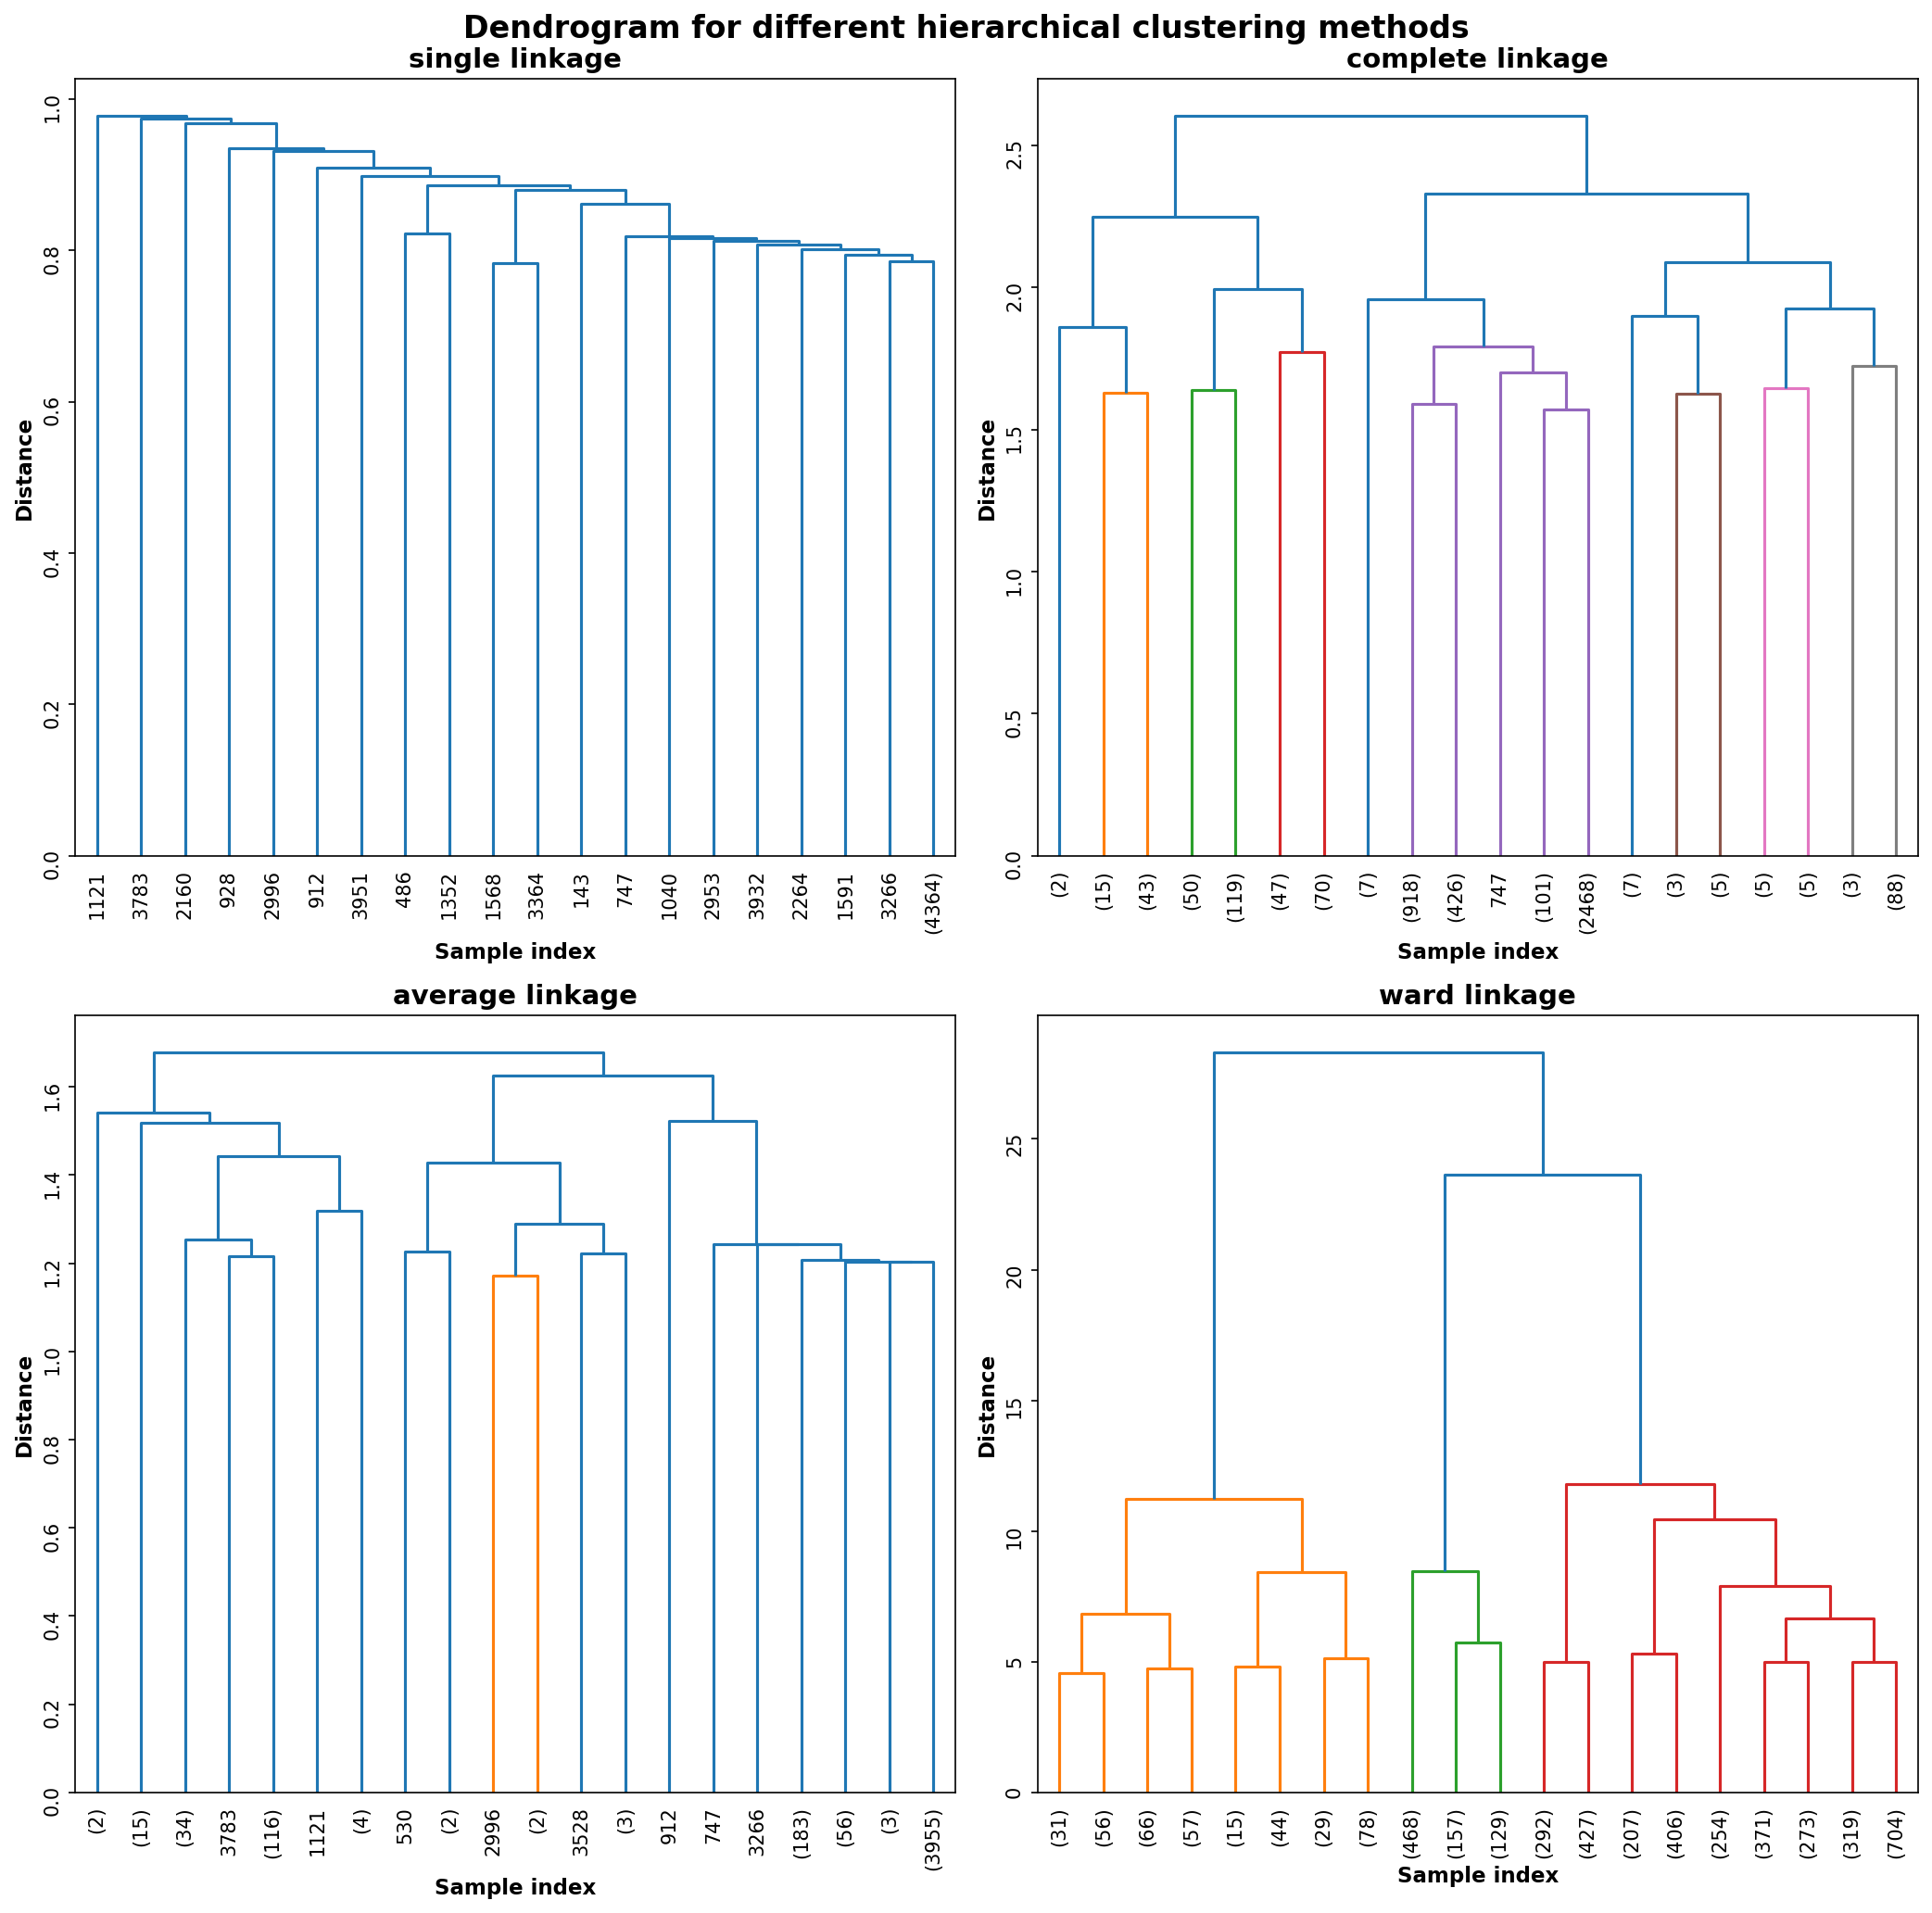

In [11]:
# Definisci i metodi di linkage da confrontare
methods = ['single', 'complete', 'average', 'ward']

fig, axs = plt.subplots(2, 2, figsize=(14, 14), dpi=150)

for ax, method in zip(axs.flatten(), methods):
    data_dist = pdist(X, metric='euclidean')
    data_link = linkage(data_dist, method=method, metric='euclidean')
    res = dendrogram(data_link, truncate_mode='lastp', ax=ax, p=20)
    ax.set_title(f'{method} linkage', fontsize=14, fontweight='bold')
    ax.tick_params(labelrotation=90, labelsize=10)
    ax.set_xlabel('Sample index', fontsize=11, fontweight='bold')
    ax.set_ylabel('Distance', fontsize=11, fontweight='bold')

fig.suptitle("Dendrogram for different hierarchical clustering methods", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### dai cophenet coefficent, avarage risulta il milgiore; gaurdando i dendogrammi ward sembra più robusto. Eseguiamo entrambi i metodi


Metodo: WARD
k=2: Silhouette=0.4987, CH=1300.70
k=3: Silhouette=0.3278, CH=1390.97
k=4: Silhouette=0.1194, CH=1093.32
k=5: Silhouette=0.1223, CH=948.09
k=6: Silhouette=0.1001, CH=858.97
k=7: Silhouette=0.1057, CH=776.94
k=8: Silhouette=0.1090, CH=722.48
k=9: Silhouette=0.1068, CH=679.29
k=10: Silhouette=0.1083, CH=637.25
k=11: Silhouette=0.1076, CH=603.79
k=12: Silhouette=0.1107, CH=570.39
k=13: Silhouette=0.1021, CH=540.37
k=14: Silhouette=0.1015, CH=514.50
k=15: Silhouette=0.0840, CH=492.07
k=16: Silhouette=0.0850, CH=473.13
k=17: Silhouette=0.0768, CH=457.03
k=18: Silhouette=0.0789, CH=442.37
k=19: Silhouette=0.0793, CH=429.44

Cophenetic Correlation Coefficient: 0.7574

Metodo: AVERAGE
k=2: Silhouette=0.5506, CH=952.38
k=3: Silhouette=0.5324, CH=506.06
k=4: Silhouette=0.5288, CH=341.07
k=5: Silhouette=0.4887, CH=257.68
k=6: Silhouette=0.4859, CH=222.22
k=7: Silhouette=0.4848, CH=188.63
k=8: Silhouette=0.4736, CH=162.91
k=9: Silhouette=0.4720, CH=143.05
k=10: Silhouette=0.4698, CH=

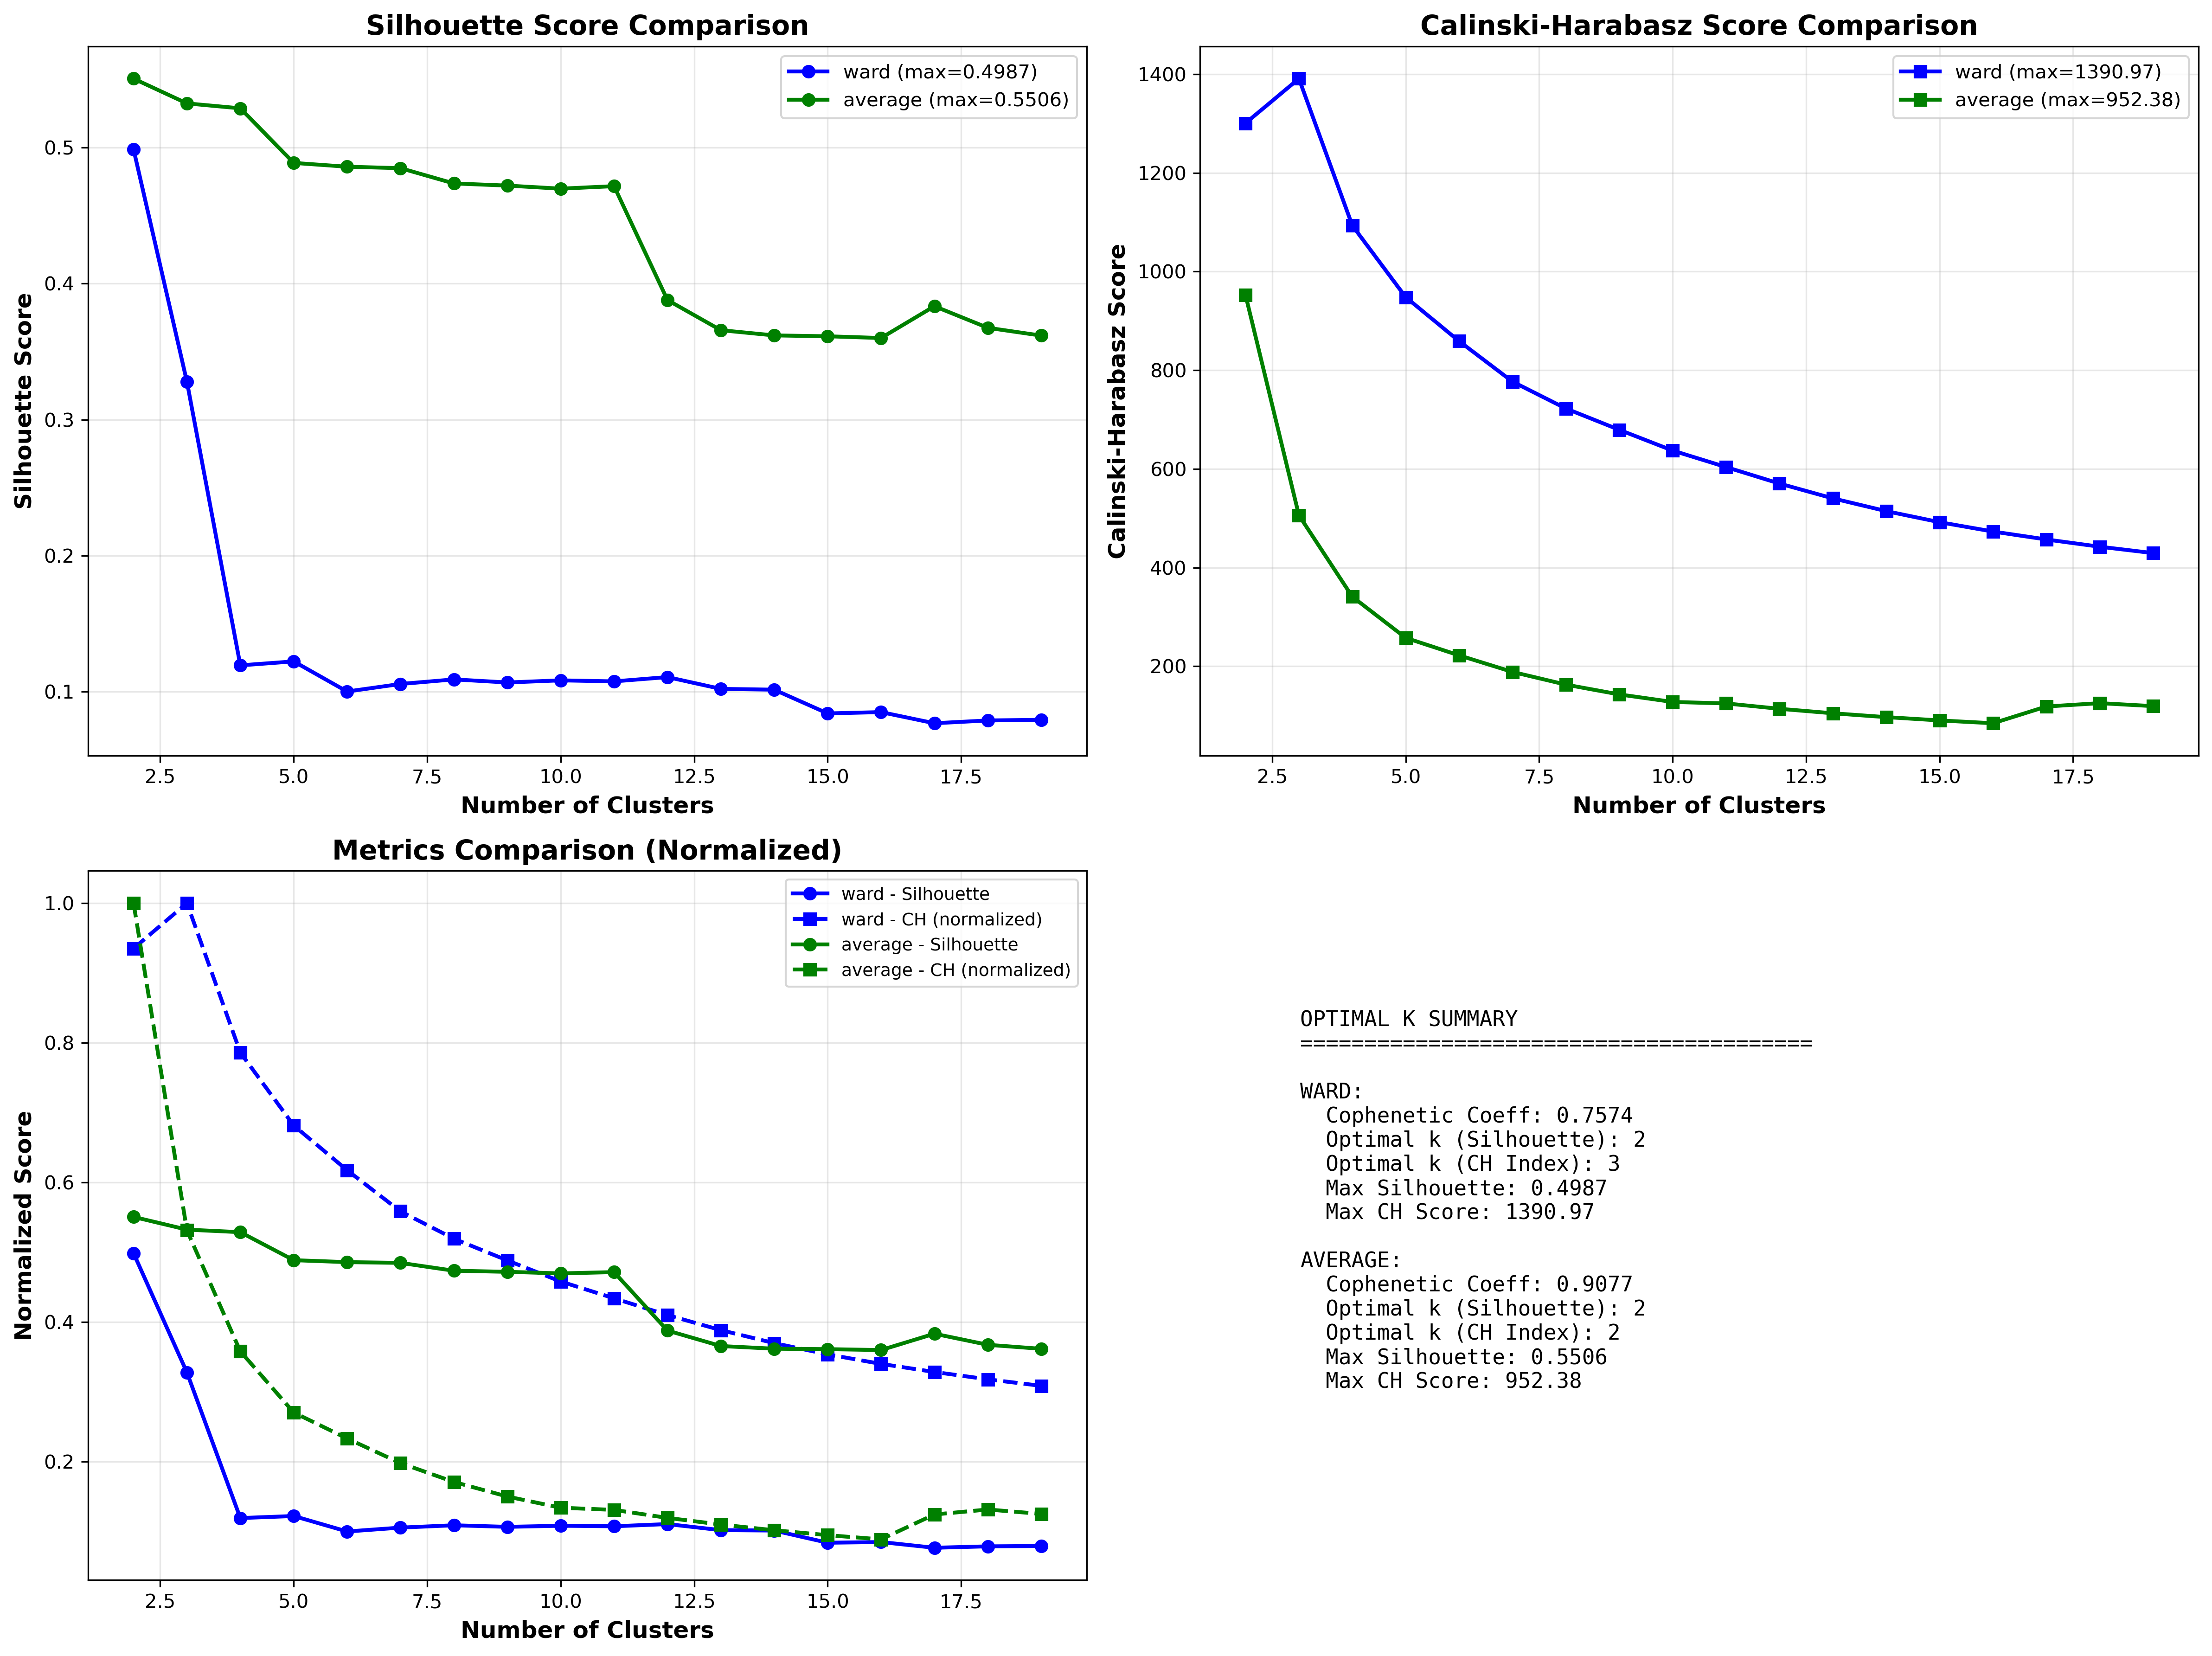


FINAL SUMMARY
OPTIMAL K SUMMARY

WARD:
  Cophenetic Coeff: 0.7574
  Optimal k (Silhouette): 2
  Optimal k (CH Index): 3
  Max Silhouette: 0.4987
  Max CH Score: 1390.97

AVERAGE:
  Cophenetic Coeff: 0.9077
  Optimal k (Silhouette): 2
  Optimal k (CH Index): 2
  Max Silhouette: 0.5506
  Max CH Score: 952.38




In [12]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import cophenet

# Metodi da confrontare
methods_to_compare = ['ward', 'average']
k_range = range(2, 20)

# Dizionari per salvare i risultati
results = {}

# Calcola le metriche per ogni metodo
for method in methods_to_compare:
    print(f"\n{'='*60}")
    print(f"Metodo: {method.upper()}")
    print(f"{'='*60}")
    
    # Crea il linkage con il metodo corrente
    data_dist = pdist(X, metric='euclidean')
    data_link = linkage(data_dist, method=method, metric='euclidean')
    
    silhouette_scores = []
    calinski_harabasz_scores = []
    
    # Calcola le metriche per ogni k
    for k in k_range:
        cluster_labels = fcluster(data_link, t=k, criterion='maxclust')
        
        sil_score = silhouette_score(X, cluster_labels, metric='euclidean')
        ch_score = calinski_harabasz_score(X, cluster_labels)
        
        silhouette_scores.append(sil_score)
        calinski_harabasz_scores.append(ch_score)
        
        print(f"k={k}: Silhouette={sil_score:.4f}, CH={ch_score:.2f}")
    
    # Calcola il Cophenetic Correlation Coefficient
    coph_corr, coph_dists = cophenet(data_link, data_dist)
    print(f"\nCophenetic Correlation Coefficient: {coph_corr:.4f}")
    
    # Salva i risultati
    results[method] = {
        'silhouette': silhouette_scores,
        'calinski_harabasz': calinski_harabasz_scores,
        'cophenetic': coph_corr,
        'linkage': data_link
    }

# Visualizza il confronto
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=300)

colors = {'ward': 'blue', 'average': 'green'}

# Plot 1: Silhouette Score
for method in methods_to_compare:
    axes[0, 0].plot(k_range, results[method]['silhouette'], 
                    marker='o', linewidth=2, markersize=6, 
                    label=f'{method} (max={max(results[method]["silhouette"]):.4f})',
                    color=colors[method])
axes[0, 0].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Silhouette Score', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Silhouette Score Comparison', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# Plot 2: Calinski-Harabasz Score
for method in methods_to_compare:
    axes[0, 1].plot(k_range, results[method]['calinski_harabasz'], 
                    marker='s', linewidth=2, markersize=6, 
                    label=f'{method} (max={max(results[method]["calinski_harabasz"]):.2f})',
                    color=colors[method])
axes[0, 1].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Calinski-Harabasz Score', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Calinski-Harabasz Score Comparison', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# Plot 3: Normalized Comparison
for method in methods_to_compare:
    sil_norm = np.array(results[method]['silhouette'])
    axes[1, 0].plot(k_range, sil_norm, 
                    marker='o', linewidth=2, markersize=6, 
                    label=f'{method} - Silhouette',
                    color=colors[method], linestyle='-')
    
    ch_norm = np.array(results[method]['calinski_harabasz']) / np.max(results[method]['calinski_harabasz'])
    axes[1, 0].plot(k_range, ch_norm, 
                    marker='s', linewidth=2, markersize=6, 
                    label=f'{method} - CH (normalized)',
                    color=colors[method], linestyle='--')

axes[1, 0].set_xlabel('Number of Clusters', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Normalized Score', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Metrics Comparison (Normalized)', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend(fontsize=9)

# Plot 4: Summary with optimal k
optimal_ks = {}
for method in methods_to_compare:
    optimal_k_sil = k_range[np.argmax(results[method]['silhouette'])]
    optimal_k_ch = k_range[np.argmax(results[method]['calinski_harabasz'])]
    optimal_ks[method] = {'silhouette': optimal_k_sil, 'calinski_harabasz': optimal_k_ch}

# Tabella riepilogativa
summary_text = "OPTIMAL K SUMMARY\n" + "="*40 + "\n\n"
for method in methods_to_compare:
    summary_text += f"{method.upper()}:\n"
    summary_text += f"  Cophenetic Coeff: {results[method]['cophenetic']:.4f}\n"
    summary_text += f"  Optimal k (Silhouette): {optimal_ks[method]['silhouette']}\n"
    summary_text += f"  Optimal k (CH Index): {optimal_ks[method]['calinski_harabasz']}\n"
    summary_text += f"  Max Silhouette: {max(results[method]['silhouette']):.4f}\n"
    summary_text += f"  Max CH Score: {max(results[method]['calinski_harabasz']):.2f}\n\n"

axes[1, 1].text(0.1, 0.5, summary_text, fontsize=11, family='monospace',
                verticalalignment='center', transform=axes[1, 1].transAxes)
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print("FINAL SUMMARY")
print(f"{'='*60}")
print(summary_text)

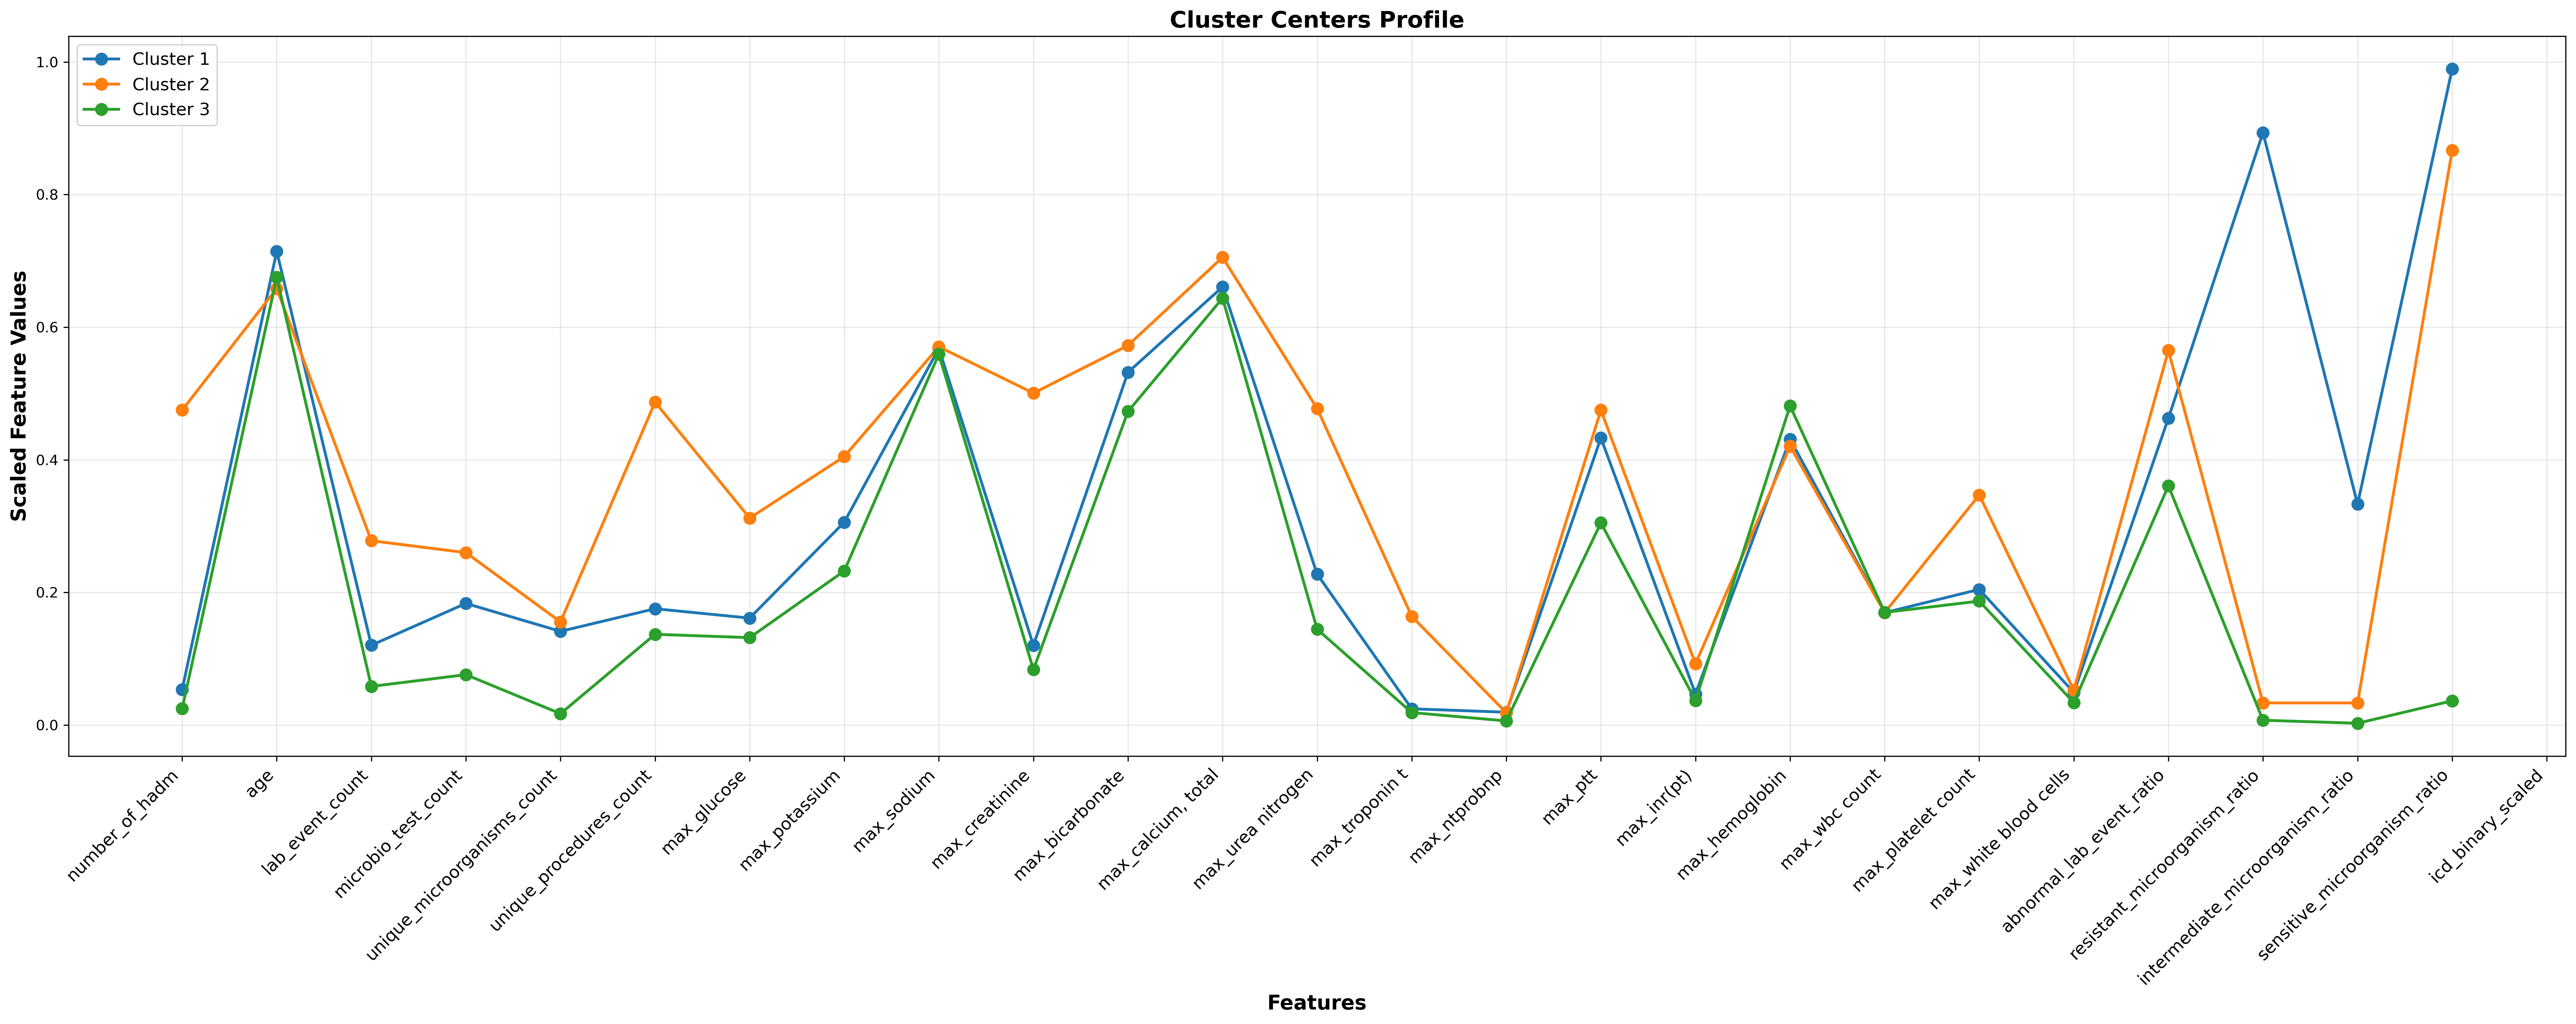

In [13]:
used_k = 3
# Get cluster labels
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')

# Add cluster labels to the dataframe
profile_df['cluster'] = cluster_labels

# Compute cluster centers (mean of each feature per cluster)
# Use the scaled data X and the numeric column names
feature_names = numeric_cols + ['icd_binary_scaled']
X_with_labels = np.column_stack([X, cluster_labels])

# Calculate centers for each cluster
centers = []
for cluster_id in range(1, used_k + 1):
    cluster_mask = cluster_labels == cluster_id
    cluster_center = X[cluster_mask].mean(axis=0)
    centers.append(cluster_center)

centers = np.array(centers)

# Plot cluster centers
plt.figure(figsize=(25, 10), dpi=300)
for i in range(len(centers)):
    plt.plot(centers[i], marker='o', label='Cluster %s' % (i + 1), linewidth=2, markersize=8)

plt.tick_params(axis='both', which='major', labelsize=10)
plt.xticks(range(len(feature_names)), feature_names, fontsize=12, rotation=45, ha='right')
plt.xlabel('Features', fontsize=14, fontweight='bold')
plt.ylabel('Scaled Feature Values', fontsize=14, fontweight='bold')
plt.title('Cluster Centers Profile', fontsize=16, fontweight='bold')
plt.legend(fontsize=12, loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ValueError: x and y must have same first dimension, but have shapes (27,) and (26,)

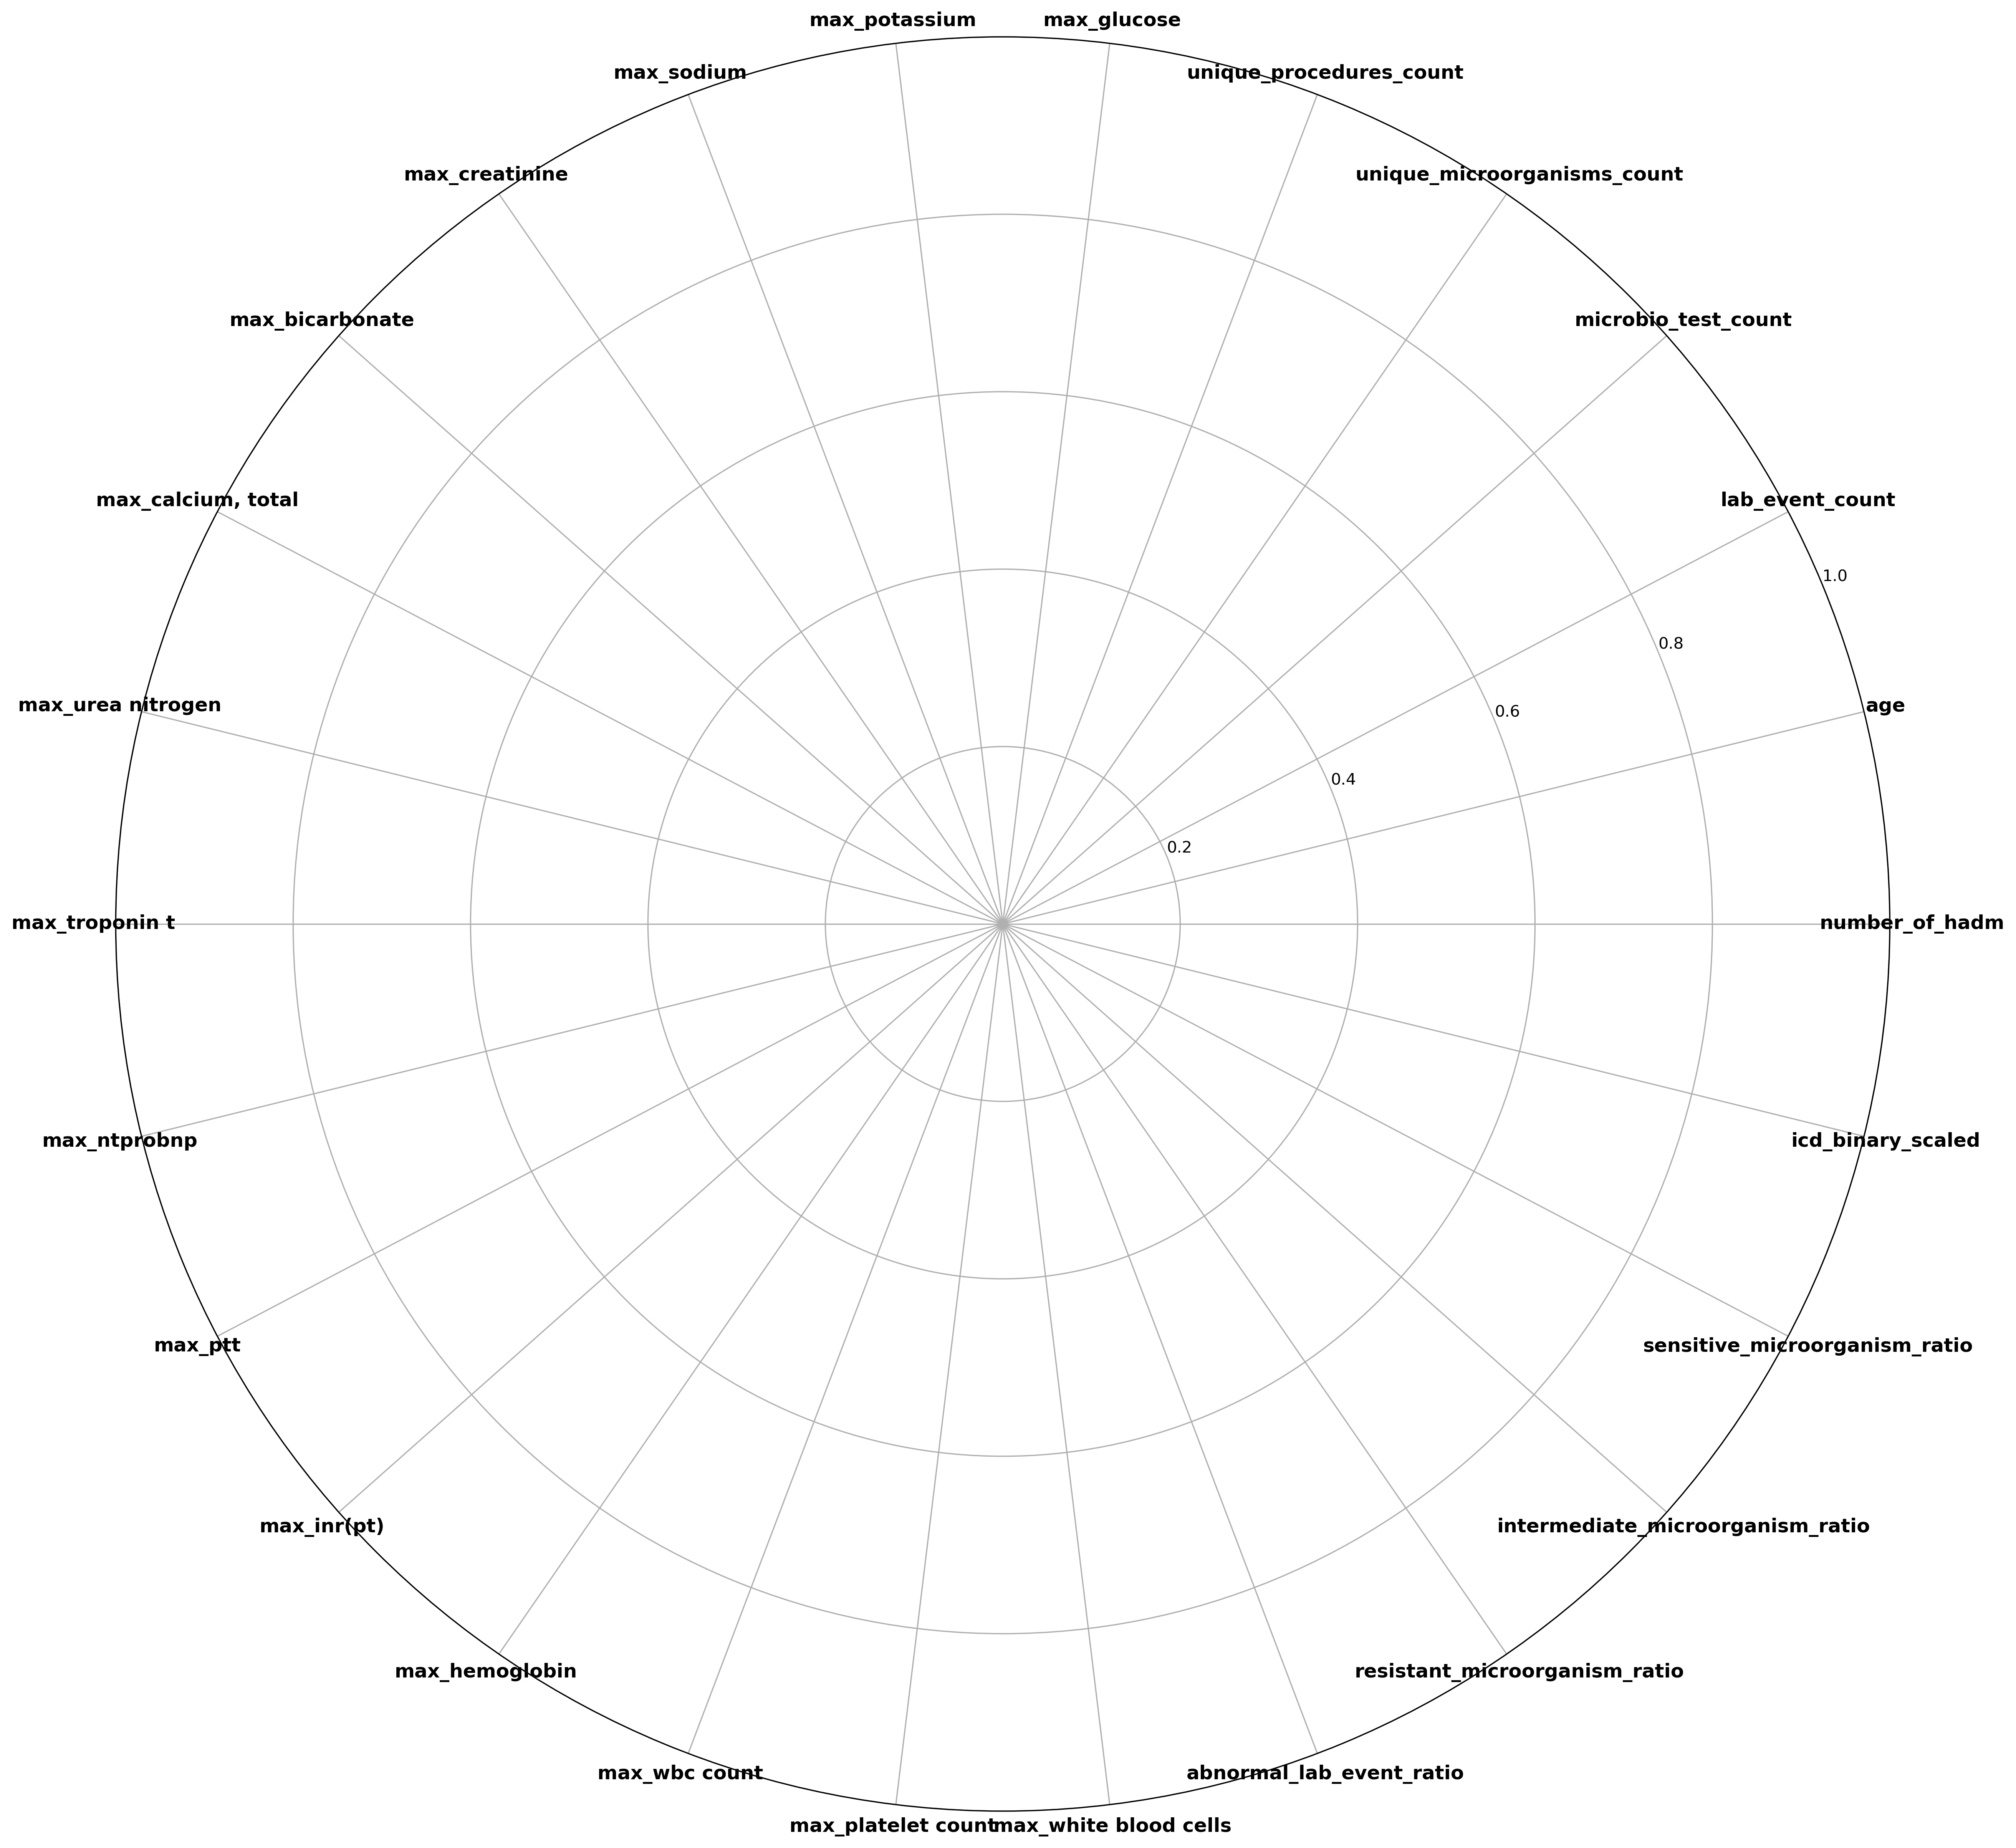

In [14]:
from math import pi
from matplotlib.colors import ListedColormap

# Number of features
N = len(feature_names)

# Get number of clusters
n_clusters = len(centers)

# Create a color palette with exactly n_clusters colors
if n_clusters <= 10:
    colors_list = plt.cm.tab10(np.linspace(0, 1, 10))[:n_clusters]
else:
    colors_list = plt.cm.tab20(np.linspace(0, 1, 20))[:n_clusters]

# Create ONE radar plot with all clusters overlapped
fig = plt.figure(figsize=(20,20), dpi=300)
ax = plt.subplot(111, polar=True)

# Calculate angles for each feature
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Complete the circle

# Draw one axis per variable and add labels with better visibility
plt.xticks(angles[:-1], feature_names, color='black', size=12, fontweight='bold')

# Plot all clusters on the same radar chart
for i in range(len(centers)):
    values = centers[i].tolist()
    values += values[:1]  # Complete the circle
    
    # Plot data with unique color for each cluster
    ax.plot(angles, values, linewidth=3, linestyle='solid', 
            label=f'Cluster {i+1}', color=colors_list[i])
    
    # Fill area with the same color
    ax.fill(angles, values, alpha=0.15, color=colors_list[i])

# Set y-axis limits
ax.set_ylim(0, 1)

# Increase y-axis tick label size
ax.tick_params(axis='y', labelsize=8)

# Add title
ax.set_title('All Clusters Profile Comparison', size=18, fontweight='bold', pad=40)

# Add legend
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=13, 
           title='Clusters', title_fontsize=14, frameon=True, shadow=True)

# Add grid
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7)

plt.tight_layout()
plt.show()


Number of subjects in each cluster:
Cluster 1: 373 subjects
Cluster 2: 4010 subjects


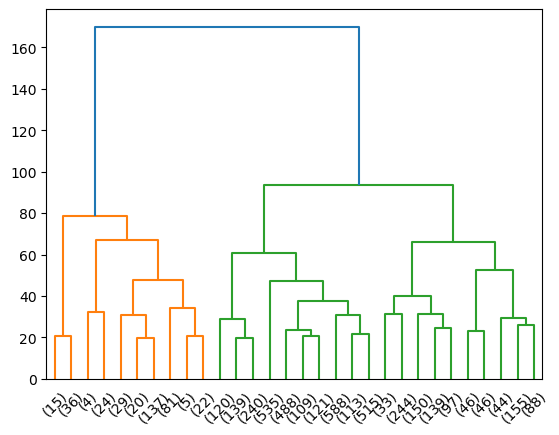

In [ ]:
# Calculate the threshold based on optimal_k
# Get the linkage distances
distances = data_link[:, 2]
# Find the threshold that gives us optimal_k clusters
threshold_index = len(data_link) - used_k + 1
color_threshold = data_link[threshold_index, 2] if threshold_index < len(data_link) else data_link[-1, 2]

res = dendrogram(
    data_link, 
    color_threshold=color_threshold,
    truncate_mode='lastp',
)

# Print the number of subjects in each cluster
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
profile_df['cluster'] = cluster_labels
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print("\nNumber of subjects in each cluster:")
for cluster_id, count in cluster_counts.items():
    print(f"Cluster {cluster_id}: {count} subjects")    


# Plots

## Age vs Number of admission scatter plot

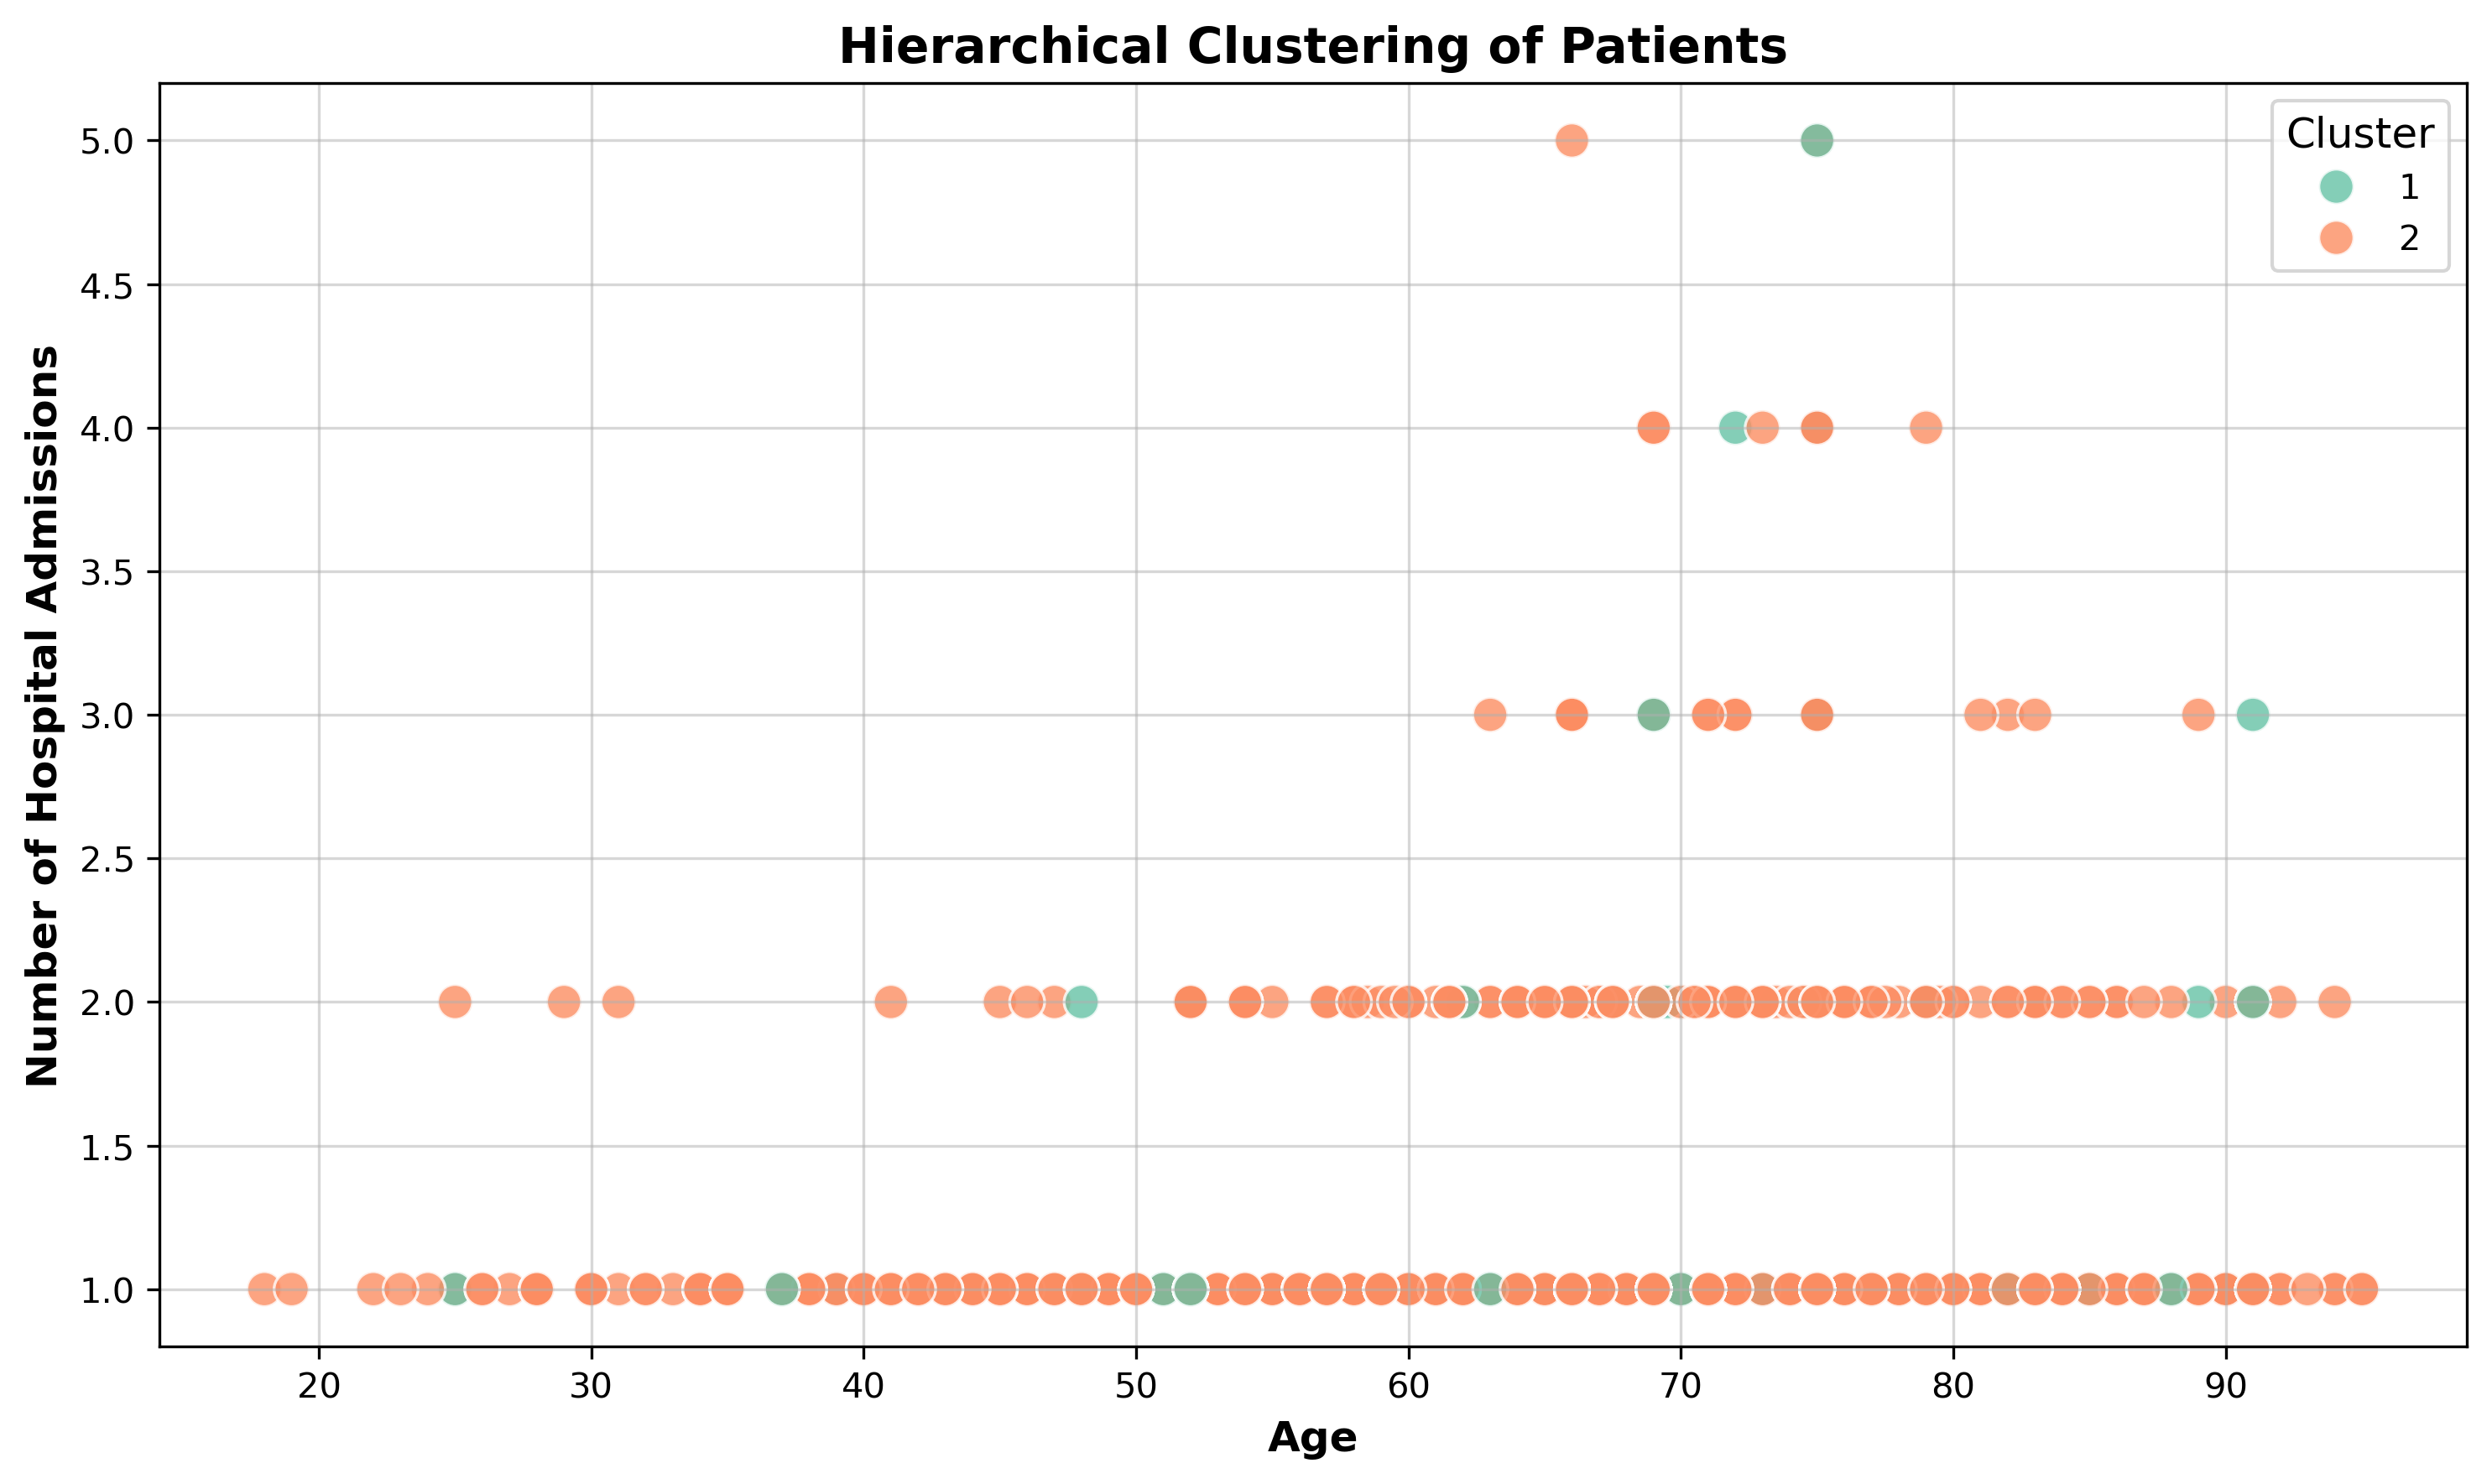

In [ ]:
# Scatter plot of clusters
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
plt.figure(figsize=(10, 6), dpi=300)
sns.scatterplot(x=profile_df['age'], y=profile_df['number_of_hadm'], hue=cluster_labels, palette='Set2', s=100, alpha=0.8)
plt.xlabel('Age', fontsize=12, fontweight='bold')
plt.ylabel('Number of Hospital Admissions', fontsize=12, fontweight='bold')
plt.title('Hierarchical Clustering of Patients', fontsize=14, fontweight='bold')
plt.legend(title='Cluster', fontsize=10, title_fontsize=12)
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show() 

## Number of organism vs Number of antibiotic scatter plot

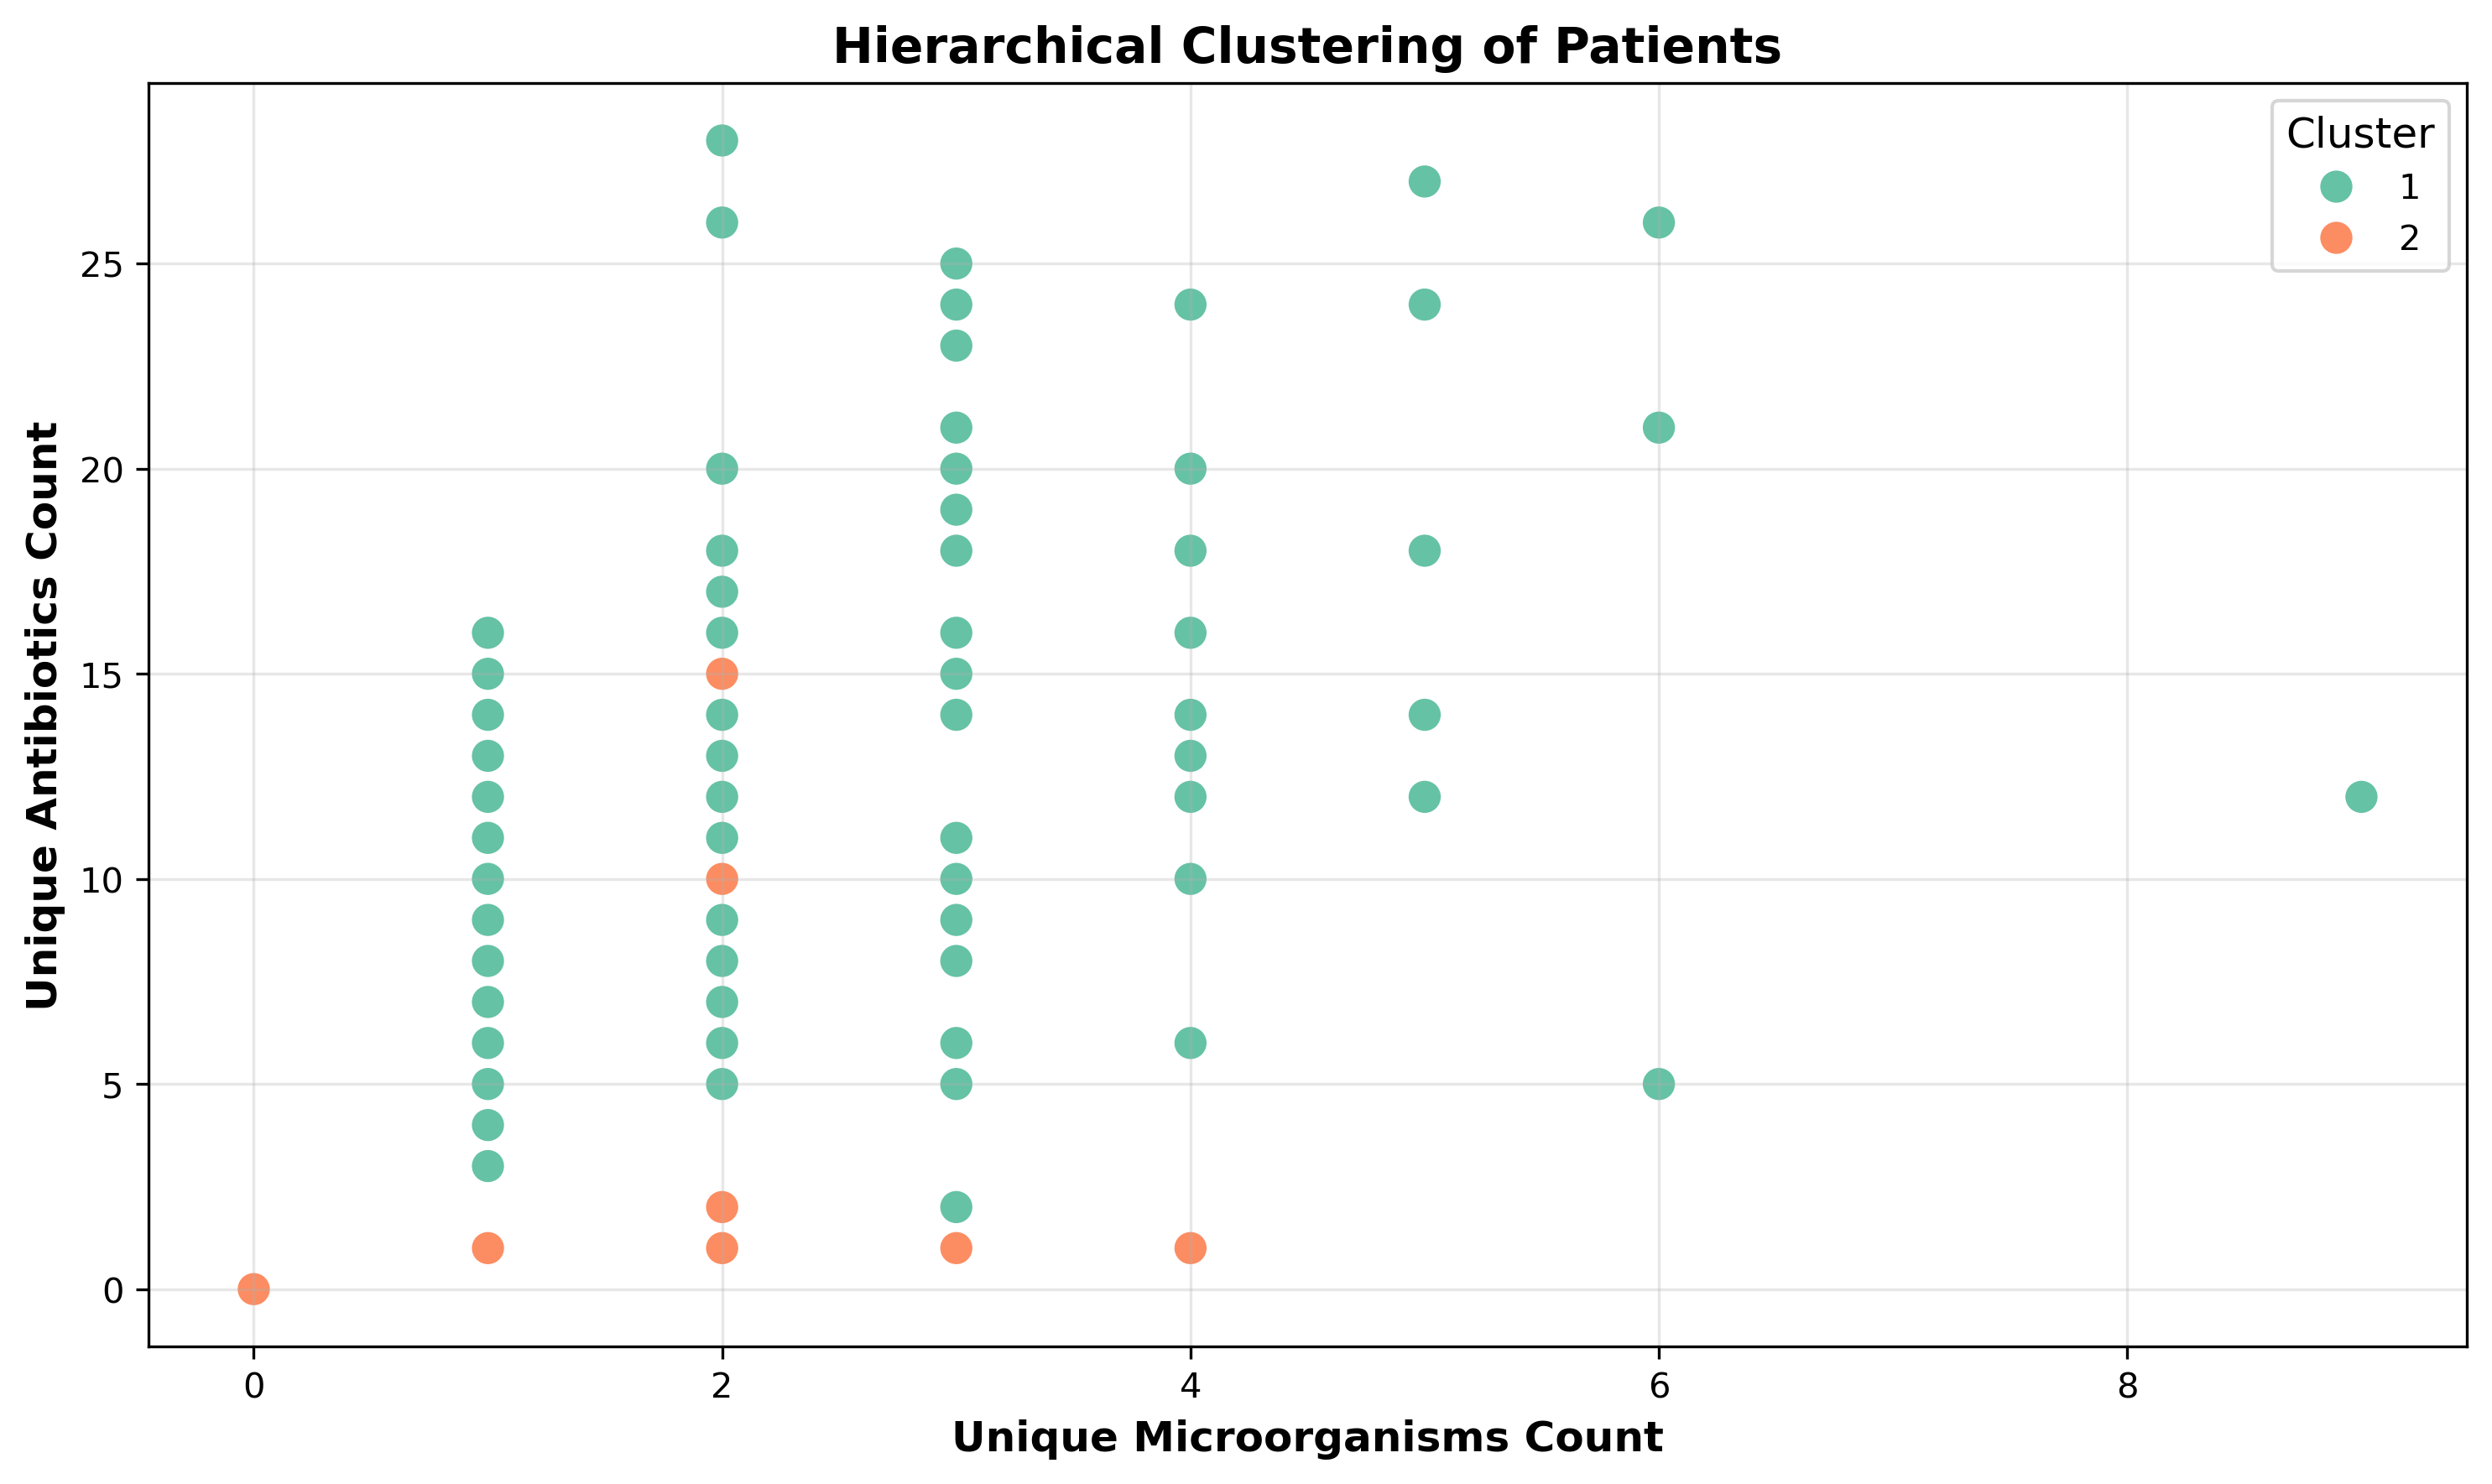

In [ ]:
# Scatter plot of clusters
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
plt.figure(figsize=(10, 6), dpi=300)
sns.scatterplot(x=profile_df['unique_microorganisms_count'], y=profile_df['unique_antibiotics_count'], hue=cluster_labels, palette='Set2', s=100)
plt.xlabel('Unique Microorganisms Count', fontsize=12, fontweight='bold')
plt.ylabel('Unique Antibiotics Count', fontsize=12, fontweight='bold')
plt.title('Hierarchical Clustering of Patients', fontsize=14, fontweight='bold')
plt.legend(title='Cluster', fontsize=10, title_fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Number of lab events vs Number of abnormal lab events

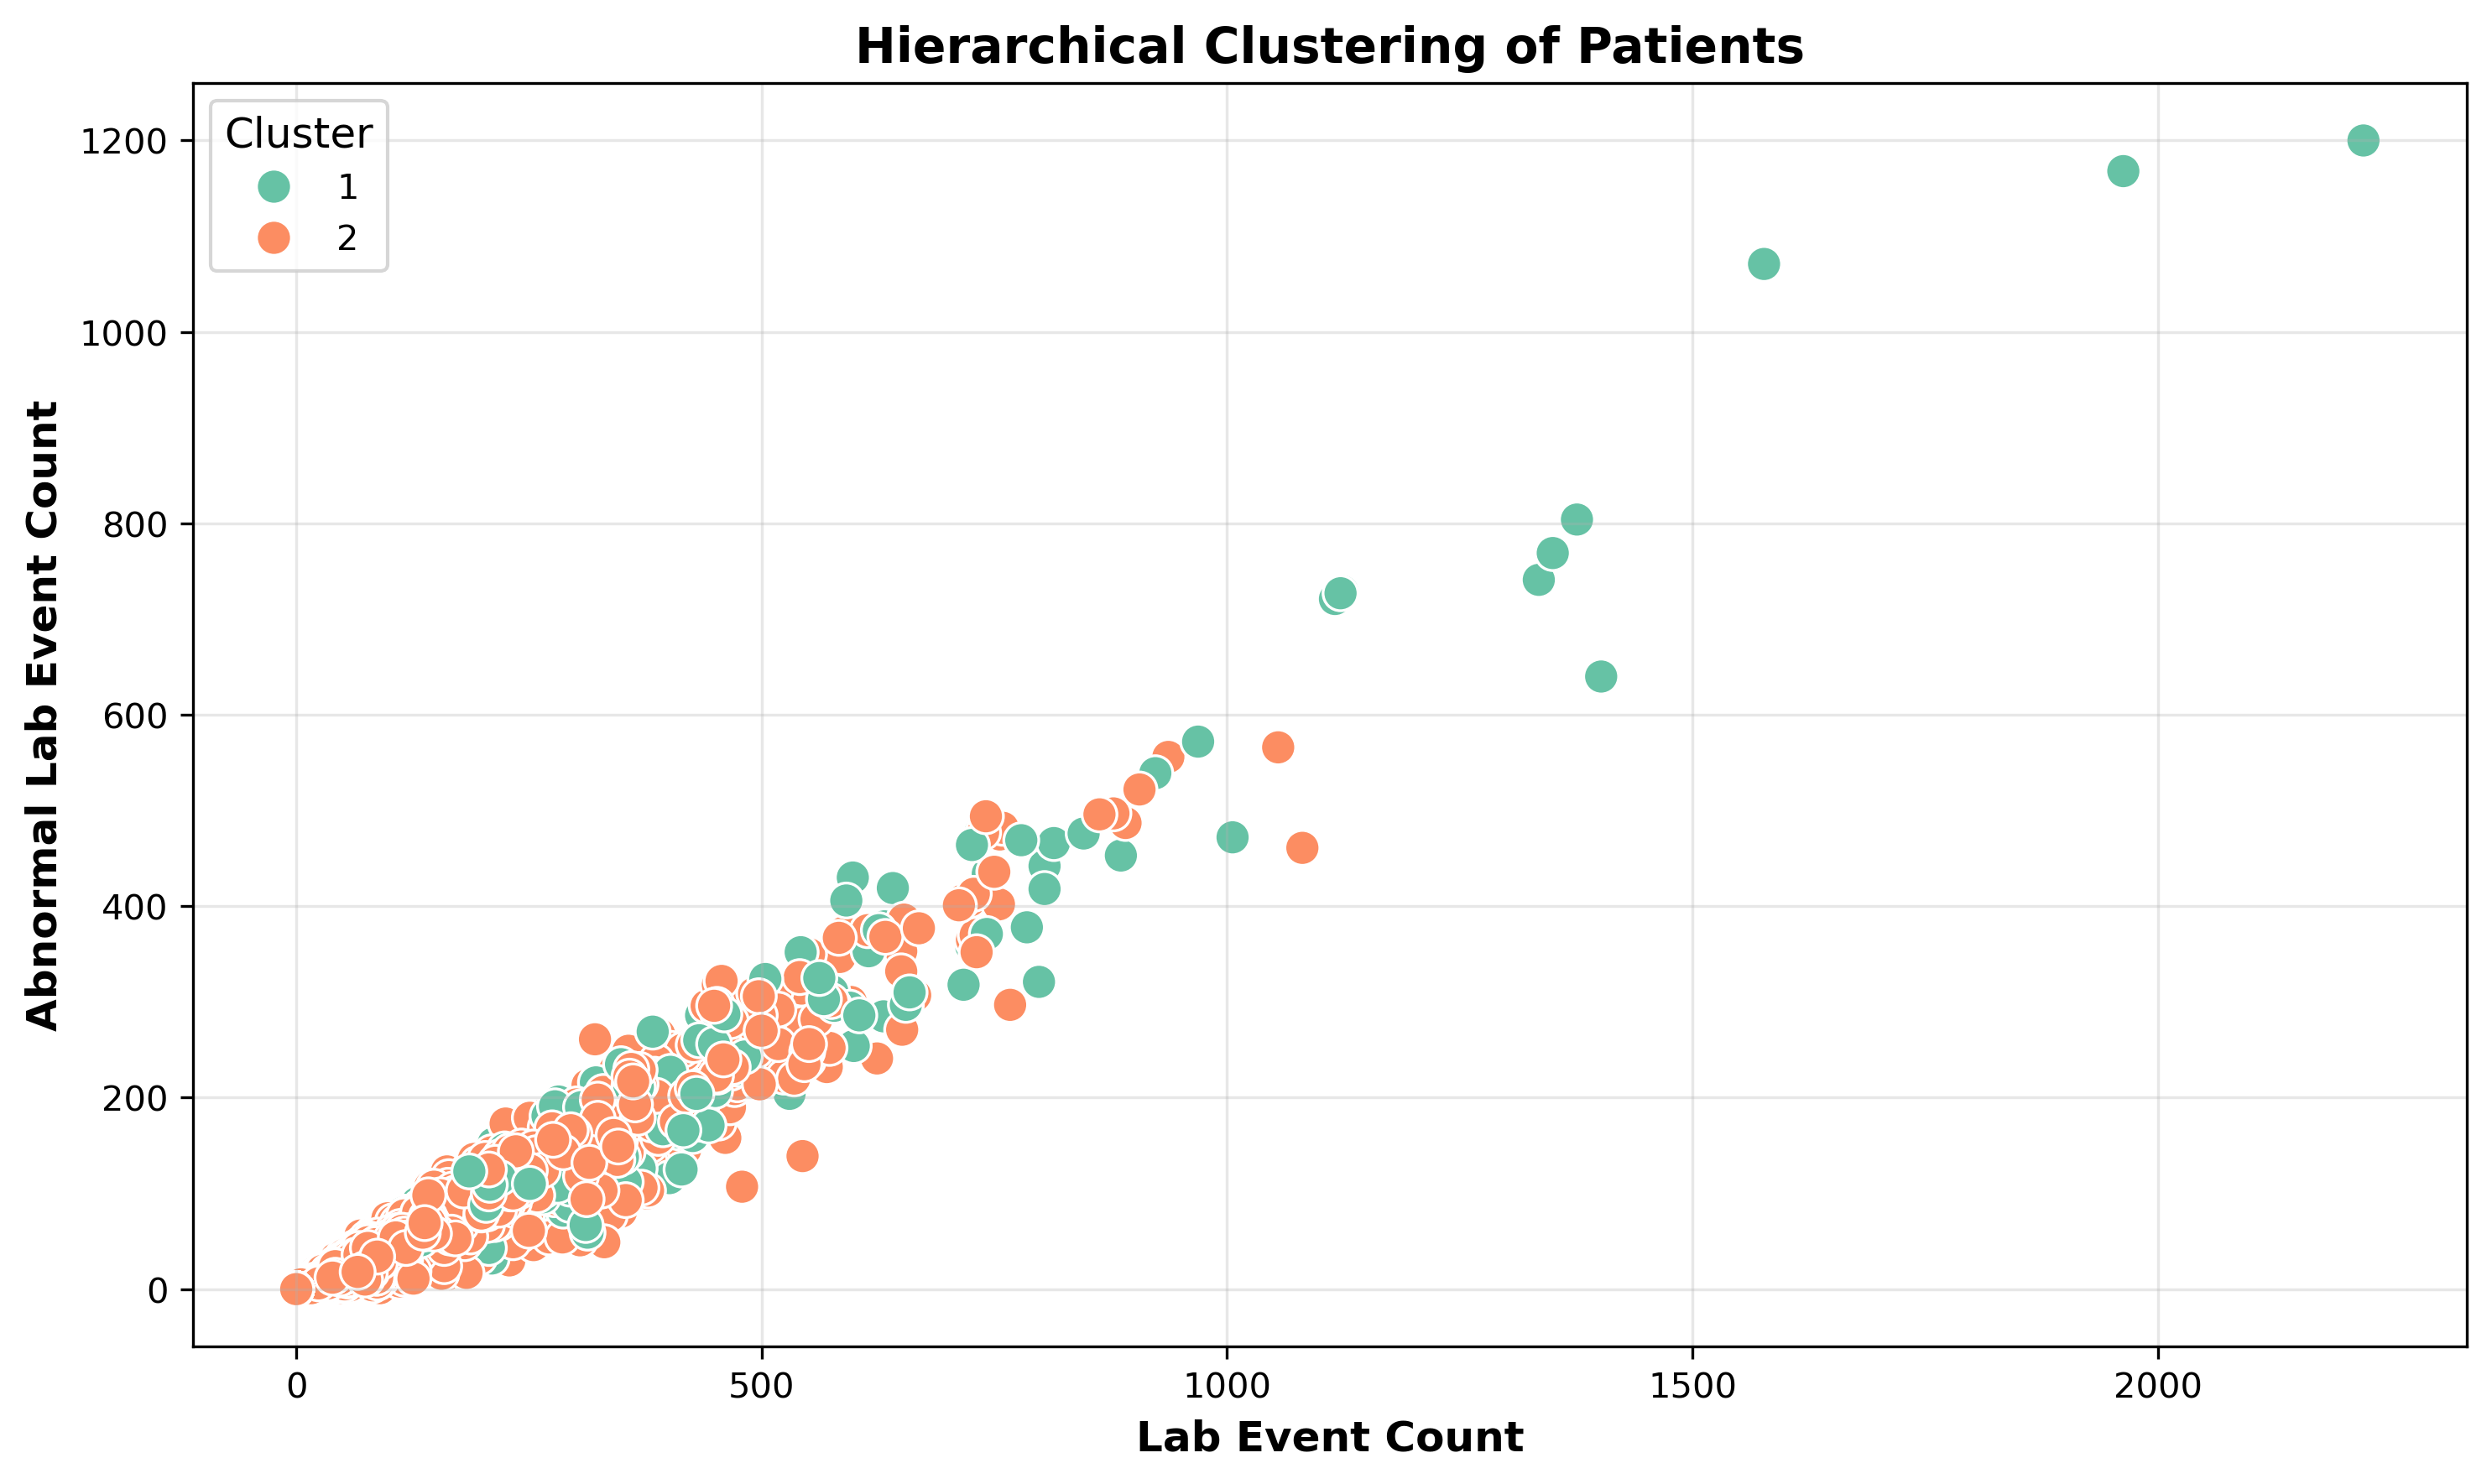

In [ ]:
# Scatter plot of clusters
cluster_labels = fcluster(data_link, t=used_k, criterion='maxclust')
plt.figure(figsize=(10, 6), dpi=300)
sns.scatterplot(x=profile_df['lab_event_count'], y=profile_df['abnormal_lab_event_count'], hue=cluster_labels, palette='Set2', s=100)
plt.xlabel('Lab Event Count', fontsize=12, fontweight='bold')
plt.ylabel('Abnormal Lab Event Count', fontsize=12, fontweight='bold')
plt.title('Hierarchical Clustering of Patients', fontsize=14, fontweight='bold')
plt.legend(title='Cluster', fontsize=10, title_fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()